# Stage 5b – Decision KPIs and their validation (RQ4, H4)

Computes per-segment KPIs from the model's churn probabilities and checks them against what really happened to the 1,407 test customers.

**Design:**
1. Thresholds, CLV, $d$, $f$ and $\gamma$ are fixed from the training data.
2. KPIs per segment: **revenue at risk** (RaR, annual), customers to contact, budget, expected campaign profit, share of a 20% contact budget.
3. **H4:** KPIs from calibrated probabilities are closer to reality than from uncalibrated ones. Tested on **value-weighted LightGBM, raw vs calibrated** (the primary model is already calibrated and is reported as an accuracy check).
4. Endpoint: $\mathrm{SAE} = \sum_s |\widehat{\mathrm{RaR}}_s - \mathrm{RaR}_s|$; paired bootstrap (2,000 resamples, stratified by segment) of $\mathrm{SAE}_{raw} - \mathrm{SAE}_{cal}$. Supported if the 95% interval is above 0.

## Step 1 – Setup

In [1]:
# Cell 1 - Setup
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import config as C
from src import modelling as M

train = pd.read_csv(C.PROCESSED_DIR / "train_segmented.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test_segmented.csv")
oof = pd.read_csv(C.PROCESSED_DIR / "stage3_oof_predictions.csv")
tst = pd.read_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv")
assert (oof[C.ID_COL] == train[C.ID_COL]).all() and (tst[C.ID_COL] == test[C.ID_COL]).all()

stage4 = joblib.load(C.MODELS_DIR / "stage4_thresholds.joblib")
SEGMENTS = ["Low-value", "New high-value", "Established high-value"]
D, F, GAMMA = stage4["incentive_d"], C.CONTACT_COST, C.ACCEPTANCE_RATE
y_tr, y_te = train[C.TARGET].to_numpy(), test[C.TARGET].to_numpy()
clv_tr, clv_te = np.asarray(M.customer_value(train)), np.asarray(M.customer_value(test))
seg_tr, seg_te = train["segment"].to_numpy(), test["segment"].to_numpy()
selected = (pd.read_csv(C.TABLES_DIR / "15_cv_selected_calibration.csv")
            .set_index(["model", "condition"])["calibration"])

# The three probability sources
VW_CAL = selected[("LightGBM", "value")]
SOURCES = {
    "Primary (LightGBM, no weights)": "LightGBM|none|raw",
    "Value-weighted, raw": "LightGBM|value|raw",
    f"Value-weighted, calibrated ({VW_CAL})": f"LightGBM|value|{VW_CAL}",
}
P_TR = {k: oof[c].to_numpy() for k, c in SOURCES.items()}
P_TE = {k: tst[c].to_numpy() for k, c in SOURCES.items()}
PRIMARY = list(SOURCES)[0]

COL = {PRIMARY: "#eda100", "Value-weighted, raw": "#9a9993", list(SOURCES)[2]: "#2a78d6"}
SEG_COLOURS = {"Low-value": "#2a78d6", "New high-value": "#1baf7a", "Established high-value": "#4a3aa7"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
                     "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png"); print("Saved figure:", name)
def save_table(df, name):
    df.to_csv(C.TABLES_DIR / f"{name}.csv"); print("Saved table:", name)

print("Calibrator of the value-weighted model (selected in Stage 3):", VW_CAL)
print(f"d = {D:.2f}, f = {F}, gamma = {GAMMA}")
for k, p in P_TE.items():
    print(f"{k:42s} mean predicted (test) = {p.mean():.3f}   observed = {y_te.mean():.3f}")

Calibrator of the value-weighted model (selected in Stage 3): Platt
d = 39.00, f = 1.0, gamma = 0.3
Primary (LightGBM, no weights)             mean predicted (test) = 0.273   observed = 0.266
Value-weighted, raw                        mean predicted (test) = 0.475   observed = 0.266
Value-weighted, calibrated (Platt)         mean predicted (test) = 0.272   observed = 0.266


## Step 2 – Contact thresholds for each probability source
The primary model uses its Stage 4 segment thresholds; the value-weighted sources get their own, chosen the same way on their training predictions.

In [2]:
# Cell 2 - Segment thresholds (same procedure as Stage 4)
GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)

def gains(y, clv, gamma=GAMMA):
    benefit, cost = M.profit_terms(clv, D, F, gamma)
    return np.where(np.asarray(y) == 1, benefit, -cost)

def profit_curve(p, g):
    return ((p[None, :] > GRID[:, None]) * g[None, :]).sum(axis=1)

def choose_threshold(p, g, n_boot=200):
    rng = np.random.default_rng(C.RANDOM_STATE)
    best = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, len(p), len(p))
        best[b] = GRID[np.argmax(profit_curve(p[idx], g[idx]))]
    return float(np.round(np.median(best), 2))

g_tr = gains(y_tr, clv_tr)
TH = {PRIMARY: stage4["thresholds"]["LightGBM"]["P2"]}
for k in list(SOURCES)[1:]:
    TH[k] = {s: choose_threshold(P_TR[k][seg_tr == s], g_tr[seg_tr == s]) for s in SEGMENTS}
# check: the procedure reproduces the Stage 4 thresholds of the primary model
assert {s: choose_threshold(P_TR[PRIMARY][seg_tr == s], g_tr[seg_tr == s]) for s in SEGMENTS} == TH[PRIMARY]
pd.DataFrame(TH).T

,Low-value,New high-value,Established high-value
"Primary (LightGBM, no weights)",0.23,0.17,0.16
"Value-weighted, raw",0.51,0.48,0.37
"Value-weighted, calibrated (Platt)",0.21,0.20,0.15


## Step 3 – The KPIs

| KPI | Estimated | Realised |
|---|---|---|
| Revenue at risk (annual) | $\sum_{i\in s} p_i\,\mathit{CLV}_i$ | $\sum_{i\in s} y_i\,\mathit{CLV}_i$ |
| Customers to contact | $|T_s|$ | same |
| Campaign budget | $|T_s|\,(f + d)$ | same |
| Campaign profit | $\sum_{T_s} E_i$ | $\sum_{T_s} R_i$ |

Realised profit still assumes $\gamma = 0.30$ (no campaign was run).

In [3]:
# Cell 3 - KPI functions
def segment_kpis(p, y, clv, seg, th, idx=None):
    # KPIs per segment and in total; idx = optional bootstrap indices
    if idx is not None:
        p, y, clv, seg = p[idx], y[idx], clv[idx], seg[idx]
    benefit, cost = M.profit_terms(clv, D, F, GAMMA)
    E = p * benefit - (1 - p) * cost
    R = y * benefit - (1 - y) * cost
    t = np.array([th[s] for s in seg])
    contact = p > t
    rows = {}
    for s in SEGMENTS + ["Total"]:
        m = np.ones(len(p), bool) if s == "Total" else seg == s
        c = m & contact
        budget = c.sum() * (F + D)
        rows[s] = {"customers": m.sum(),
                   "RaR estimated": (p[m] * clv[m]).sum(), "RaR realised": (y[m] * clv[m]).sum(),
                   "churners estimated": p[m].sum(), "churners realised": y[m].sum(),
                   "contacted": c.sum(), "budget": budget,
                   "profit estimated": E[c].sum(), "profit realised": R[c].sum()}
        rows[s]["ROI estimated"] = rows[s]["profit estimated"] / budget if budget else np.nan
        rows[s]["ROI realised"] = rows[s]["profit realised"] / budget if budget else np.nan
    return pd.DataFrame(rows).T

KPI = {k: segment_kpis(P_TE[k], y_te, clv_te, seg_te, TH[k]) for k in SOURCES}
KPI[PRIMARY].round(1)

,customers,RaR estimated,RaR realised,churners estimated,churners realised,contacted,budget,profit estimated,profit realised,ROI estimated,ROI realised
Low-value,446.0,20887.9,18760.2,60.1,54.0,95.0,3800.0,1219.1,987.2,0.3,0.3
New high-value,523.0,234395.6,235538.4,252.5,253.0,465.0,18599.8,56973.6,55720.6,3.1,3.0
Established high-value,438.0,81954.2,75519.6,71.8,67.0,167.0,6679.9,14204.5,12260.6,2.1,1.8
Total,1407.0,337237.6,329818.2,384.4,374.0,727.0,29079.7,72397.3,68968.5,2.5,2.4


## Step 4 – Bootstrap: uncertainty and the H4 test
2,000 resamples within each segment; the same resamples for every source (paired).

In [4]:
# Cell 4 - Paired, segment-stratified bootstrap
rng = np.random.default_rng(C.RANDOM_STATE)
seg_idx = {s: np.where(seg_te == s)[0] for s in SEGMENTS}
B = C.N_BOOTSTRAP

def sae(k_df):
    return np.abs(k_df.loc[SEGMENTS, "RaR estimated"] - k_df.loc[SEGMENTS, "RaR realised"]).sum()

boot_rel = {k: {s: [] for s in SEGMENTS + ["Total"]} for k in SOURCES}
boot_sae = {k: [] for k in SOURCES}
boot_profit_err = {s: [] for s in SEGMENTS + ["Total"]}
for b in range(B):
    idx = np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in seg_idx.values()])
    for k in SOURCES:
        kd = segment_kpis(P_TE[k], y_te, clv_te, seg_te, TH[k], idx)
        for s in SEGMENTS + ["Total"]:
            boot_rel[k][s].append(kd.loc[s, "RaR estimated"] / kd.loc[s, "RaR realised"] - 1)
        boot_sae[k].append(sae(kd))
        if k == PRIMARY:
            for s in SEGMENTS + ["Total"]:
                boot_profit_err[s].append(kd.loc[s, "profit estimated"] - kd.loc[s, "profit realised"])
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
print("bootstrap done:", B, "resamples")

bootstrap done: 2000 resamples


In [5]:
# Cell 5 - Table: estimated vs realised revenue at risk (the main KPI table)
VW_RAW, VW_CALK = list(SOURCES)[1], list(SOURCES)[2]
rows = []
for s in SEGMENTS + ["Total"]:
    r = {"segment": s, "customers": int(KPI[PRIMARY].loc[s, "customers"]),
         "realised RaR": KPI[PRIMARY].loc[s, "RaR realised"]}
    for k, short in [(PRIMARY, "primary"), (VW_RAW, "VW raw"), (VW_CALK, "VW calibrated")]:
        est = KPI[k].loc[s, "RaR estimated"]
        lo, hi = ci(boot_rel[k][s])
        r[f"{short}: estimated RaR"] = est
        r[f"{short}: relative error %"] = 100 * (est / r["realised RaR"] - 1)
        r[f"{short}: 95% CI"] = f"[{100*lo:+.0f}, {100*hi:+.0f}]"
    r["contacted (primary)"] = int(KPI[PRIMARY].loc[s, "contacted"])
    r["budget (primary)"] = KPI[PRIMARY].loc[s, "budget"]
    rows.append(r)
kpi_table = pd.DataFrame(rows).set_index("segment")
save_table(kpi_table.round(1), "44_kpi_rar_validation")
kpi_table.round(1)

Saved table: 44_kpi_rar_validation


,customers,realised RaR,primary: estimated RaR,primary: relative error %,primary: 95% CI,VW raw: estimated RaR,VW raw: relative error %,VW raw: 95% CI,VW calibrated: estimated RaR,VW calibrated: relative error %,VW calibrated: 95% CI,contacted (primary),budget (primary)
segment,,,,,,,,,,,,,
Low-value,446,18760.2,20887.9,11.3,"[-11, +45]",34577.9,84.3,"[+47, +140]",16107.8,-14.1,"[-31, +12]",95,3800.0
New high-value,523,235538.4,234395.6,-0.5,"[-8, +8]",372373.1,58.1,"[+46, +72]",236254.2,0.3,"[-7, +9]",465,18599.8
Established high-value,438,75519.6,81954.2,8.5,"[-11, +37]",198133.0,162.4,"[+117, +232]",101018.5,33.8,"[+10, +69]",167,6679.9
Total,1407,329818.2,337237.6,2.2,"[-5, +10]",605084.1,83.5,"[+70, +98]",353380.5,7.1,"[-1, +16]",727,29079.7


In [6]:
# Cell 6 - H4: paired bootstrap of the difference in summed absolute error
sae_obs = {k: sae(KPI[k]) for k in SOURCES}
delta = np.array(boot_sae[VW_RAW]) - np.array(boot_sae[VW_CALK])
d_obs = sae_obs[VW_RAW] - sae_obs[VW_CALK]
h4_lo, h4_hi = ci(delta)
h4 = pd.DataFrame({
    "SAE (sum of absolute RaR errors over segments)": sae_obs,
    "SAE as % of realised RaR": {k: 100 * v / KPI[PRIMARY].loc["Total", "RaR realised"] for k, v in sae_obs.items()},
}).round(1)
print(h4.to_string())
print(f"\nH4: Delta SAE (raw - calibrated) = {d_obs:,.0f}  95% CI [{h4_lo:,.0f}, {h4_hi:,.0f}]  "
      f"-> {'SUPPORTED' if h4_lo > 0 else 'NOT supported'}")
save_table(h4.assign(**{"Delta SAE raw - calibrated": [np.nan, d_obs, np.nan],
                        "CI 2.5%": [np.nan, h4_lo, np.nan], "CI 97.5%": [np.nan, h4_hi, np.nan]}),
           "45_h4_test")

                                    SAE (sum of absolute RaR errors over segments)  SAE as % of realised RaR
Primary (LightGBM, no weights)                                              9705.0                       2.9
Value-weighted, raw                                                       275265.9                      83.5
Value-weighted, calibrated (Platt)                                         28867.0                       8.8

H4: Delta SAE (raw - calibrated) = 246,399  95% CI [206,149, 255,725]  -> SUPPORTED
Saved table: 45_h4_test


## Step 5 – Campaign profit: estimated vs label-realised (descriptive)

In [7]:
# Cell 7 - Profit, budget and ROI per segment for the three sources
rows = []
for k in SOURCES:
    for s in SEGMENTS + ["Total"]:
        kd = KPI[k].loc[s]
        rows.append({"source": k, "segment": s, "contacted": int(kd["contacted"]), "budget": kd["budget"],
                     "profit estimated": kd["profit estimated"], "profit realised": kd["profit realised"],
                     "ROI estimated": kd["ROI estimated"], "ROI realised": kd["ROI realised"]})
profit_table = pd.DataFrame(rows).set_index(["source", "segment"])
pe = {s: ci(boot_profit_err[s]) for s in SEGMENTS + ["Total"]}
print("Primary model: profit error (estimated - realised), 95% CI")
for s in SEGMENTS + ["Total"]:
    e = KPI[PRIMARY].loc[s, "profit estimated"] - KPI[PRIMARY].loc[s, "profit realised"]
    print(f"  {s:24s} {e:9,.0f}   [{pe[s][0]:,.0f}, {pe[s][1]:,.0f}]")
save_table(profit_table.round(2), "46_kpi_profit_by_source")
profit_table.round(1)

Primary model: profit error (estimated - realised), 95% CI
  Low-value                      232   [-977, 1,443]
  New high-value               1,253   [-4,930, 7,168]
  Established high-value       1,944   [-2,497, 6,418]
  Total                        3,429   [-3,908, 10,761]
Saved table: 46_kpi_profit_by_source


contacted   budget  \
source                             segment                                      
Primary (LightGBM, no weights)     Low-value                      95   3800.0   
                                   New high-value                465  18599.8   
                                   Established high-value        167   6679.9   
                                   Total                         727  29079.7   
Value-weighted, raw                Low-value                      59   2360.0   
                                   New high-value                454  18159.8   
                                   Established high-value        213   8519.9   
                                   Total                         726  29039.7   
Value-weighted, calibrated (Platt) Low-value                      59   2360.0   
                                   New high-value                454  18159.8   
                                   Established high-value        213   8519.9   
                                   Total                         726  29039.7   

                                                           profit estimated  \
source                             segment                                    
Primary (LightGBM, no weights)     Low-value                         1219.1   
                                   New high-value                   56973.6   
                                   Established high-value           14204.5   
                                   Total                            72397.3   
Value-weighted, raw                Low-value                         3992.7   
                                   New high-value                   99143.0   
                                   Established high-value           46688.3   
                                   Total                           149824.0   
Value-weighted, calibrated (Platt) Low-value                          745.6   
                                   New high-value                   57328.7   
                                   Established high-value           20140.6   
                                   Total                            78214.9   

                                                           profit realised  \
source                             segment                                   
Primary (LightGBM, no weights)     Low-value                         987.2   
                                   New high-value                  55720.6   
                                   Established high-value          12260.6   
                                   Total                           68968.5   
Value-weighted, raw                Low-value                        1247.0   
                                   New high-value                  56174.9   
                                   Established high-value          11241.0   
                                   Total                           68662.8   
Value-weighted, calibrated (Platt) Low-value                        1247.0   
                                   New high-value                  56174.9   
                                   Established high-value          11241.0   
                                   Total                           68662.8   

                                                           ROI estimated  \
source                             segment                                 
Primary (LightGBM, no weights)     Low-value                         0.3   
                                   New high-value                    3.1   
                                   Established high-value            2.1   
                                   Total                             2.5   
Value-weighted, raw                Low-value                         1.7   
                                   New high-value                    5.5   
                                   Established high-value            5.5   
                                   Total

In [8]:
# Cell 8 - Sensitivity to the acceptance rate (primary model): the RaR does not depend on gamma,
# the profit error does (gamma changes how much each customer's calibration error counts)
rows = []
for gam in [0.10, 0.30, 0.50]:
    benefit, cost = M.profit_terms(clv_te, D, F, gam)
    p = P_TE[PRIMARY]
    E = p * benefit - (1 - p) * cost; R = y_te * benefit - (1 - y_te) * cost
    t = np.array([TH[PRIMARY][s] for s in seg_te]); c = p > t
    rows.append({"gamma": gam, "profit estimated": E[c].sum(), "profit realised": R[c].sum(),
                 "relative error %": 100 * (E[c].sum() / R[c].sum() - 1)})
sens = pd.DataFrame(rows).set_index("gamma")
save_table(sens.round(2), "47_kpi_gamma_sensitivity")
sens.round(1)

Saved table: 47_kpi_gamma_sensitivity


,profit estimated,profit realised,relative error %
gamma,,,
0.1,13562.2,12130.9,11.8
0.3,72397.3,68968.5,5.0
0.5,131232.3,125806.0,4.3


## Step 6 – Robustness: does calibration lower the RaR error for other models too?
Every model × condition where Stage 3 selected a calibrator (SVM excluded).

In [9]:
# Cell 8b - Robustness count
pairs = [(m, c) for (m, c), cal in selected.items() if cal != "raw" and m != "SVM"]
tab = pd.read_csv(C.TABLES_DIR / "20_tabicl_cv_calibration.csv").set_index("calibration")["Brier"]
pairs.append(("TabICL v2", "none"))
cal_of = lambda m, c: tab.idxmin() if m == "TabICL v2" else selected[(m, c)]
rows = []
for m, c in pairs:
    def sae_of(col):
        kd = segment_kpis(tst[col].to_numpy(), y_te, clv_te, seg_te, TH[PRIMARY])
        return sae(kd)
    raw_, cal_ = sae_of(f"{m}|{c}|raw"), sae_of(f"{m}|{c}|{cal_of(m, c)}")
    rows.append({"model": m, "condition": c, "calibrator": cal_of(m, c),
                 "SAE raw": raw_, "SAE calibrated": cal_, "calibration lowers error": cal_ < raw_})
robust = pd.DataFrame(rows).set_index(["model", "condition"])
save_table(robust.round(0), "48_kpi_robustness")
print(f"Calibration lowered the RaR error in {robust['calibration lowers error'].sum()} of {len(robust)} cases")
robust.round(0)

Saved table: 48_kpi_robustness
Calibration lowered the RaR error in 10 of 11 cases


calibrator   SAE raw  SAE calibrated  \
model               condition                                        
Logistic regression class          Platt  182795.0         10351.0   
                    value       isotonic  321834.0         34337.0   
                    SMOTE          Platt  169999.0         11710.0   
Random forest       none           Platt   16003.0          8460.0   
                    class          Platt  174218.0          7777.0   
                    value          Platt  257903.0         27778.0   
                    SMOTE          Platt  151001.0          7729.0   
LightGBM            class          Platt  180078.0          9798.0   
                    value          Platt  275266.0         28867.0   
                    SMOTE          Platt  112894.0         12682.0   
TabICL v2           none           Platt    7916.0          9826.0   

                               calibration lowers error  
model               condition                            
Logistic regression class                          True  
                    value                          True  
                    SMOTE                          True  
Random forest       none                           True  
                    class                          True  
                    value                          True  
                    SMOTE                          True  
LightGBM            class                          True  
                    value                          True  
                    SMOTE                          True  
TabICL v2           none                          False

## Step 7 – Do model-based KPIs change retention priorities?
Share of a 20% contact budget per segment when ranking by churn probability vs by expected profit.

In [10]:
# Cell 9 - Priorities: descriptive vs value-based
p = P_TE[PRIMARY]
benefit, cost = M.profit_terms(clv_te, D, F, GAMMA)
E = p * benefit - (1 - p) * cost
n20 = int(round(0.20 * len(p)))
by_risk = np.argsort(-p)[:n20]
by_profit = np.argsort(-E)[:n20]
prio = pd.DataFrame({
    "observed churn rate (training)": train.groupby("segment")[C.TARGET].mean().reindex(SEGMENTS) * 100,
    "estimated RaR (test)": KPI[PRIMARY].loc[SEGMENTS, "RaR estimated"],
    "expected profit if all with E>0 contacted": [E[(seg_te == s) & (E > 0)].sum() for s in SEGMENTS],
    "share of 20% budget: rank by churn risk (%)": [100 * (seg_te[by_risk] == s).mean() for s in SEGMENTS],
    "share of 20% budget: rank by expected profit (%)": [100 * (seg_te[by_profit] == s).mean() for s in SEGMENTS],
}, index=SEGMENTS)
for col in prio.columns[:3]:
    prio[f"rank by {col.split(' (')[0]}"] = prio[col].rank(ascending=False).astype(int)
save_table(prio.round(1), "49_kpi_priorities")
prio.round(1)

Saved table: 49_kpi_priorities


,observed churn rate (training),estimated RaR (test),expected profit if all with E>0 contacted,share of 20% budget: rank by churn risk (%),share of 20% budget: rank by expected profit (%),rank by observed churn rate,rank by estimated RaR,rank by expected profit if all with E>0 contacted
Low-value,12.5,20887.9,1440.9,6.4,0.0,3,3,3
New high-value,47.3,234395.6,57040.9,89.3,85.8,1,1,1
Established high-value,15.5,81954.2,14456.4,4.3,14.2,2,2,2


## Step 8 – Figure

Saved figure: 20_kpi_rar_validation


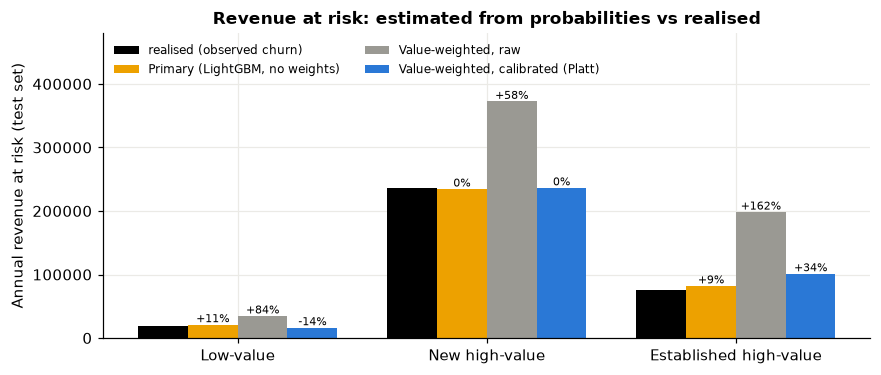

In [11]:
# Cell 10 - Estimated vs realised revenue at risk per segment
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(3); w = 0.2
real = KPI[PRIMARY].loc[SEGMENTS, "RaR realised"].to_numpy()
ax.bar(x - 1.5 * w, real, w, color="black", label="realised (observed churn)")
for j, k in enumerate(SOURCES):
    est = KPI[k].loc[SEGMENTS, "RaR estimated"].to_numpy()
    lo = np.array([np.percentile(boot_rel[k][s], 2.5) for s in SEGMENTS])
    hi = np.array([np.percentile(boot_rel[k][s], 97.5) for s in SEGMENTS])
    rel = est / real - 1
    ax.bar(x + (j - 0.5) * w, est, w, color=COL[k], label=k)
    for xi, e, r_, l_, h_ in zip(x + (j - 0.5) * w, est, rel, lo, hi):
        ax.text(xi, e, f"{100*r_ + 0:+.0f}%".replace("-0%", "0%").replace("+0%", "0%"), ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, SEGMENTS); ax.set_ylabel("Annual revenue at risk (test set)"); ax.set_ylim(0, 480000)
ax.set_title("Revenue at risk: estimated from probabilities vs realised")
ax.legend(fontsize=8, ncol=2, loc="upper left")
save(fig, "20_kpi_rar_validation")
plt.show()

## Step 9 – Save for the dashboard

In [12]:
# Cell 11 - Save KPI results for Stage 6
joblib.dump({"thresholds": TH, "kpis": KPI, "kpi_table": kpi_table, "h4": {"delta": d_obs, "ci": (h4_lo, h4_hi)},
             "priorities": prio}, C.MODELS_DIR / "stage5b_kpis.joblib")
print("Saved outputs/models/stage5b_kpis.joblib")

Saved outputs/models/stage5b_kpis.joblib


## Findings
**1. The primary model's KPIs are accurate:** estimated revenue at risk 337k vs 330k actually lost (**+2.2%**, 95% CI −5% to +10%); every segment's interval includes zero (low-value +11%, new high-value −0.5%, established high-value +9%). Expected profit 72.4k vs label-realised 69.0k. With only 54 low-value churners, errors of about ±25% there cannot be detected.

**2. H4 is supported:** value-weighted raw probabilities overstated revenue at risk by **84%**; after calibration **7%**. Reduction in summed absolute error: **246k** (95% CI 206k to 256k). Calibration lowered the error in 10 of 11 model/condition cases (exception: TabICL, already calibrated).

**3. Global calibration does not calibrate each segment:** after calibration, established high-value revenue at risk is still overstated by **34%** (95% CI +10% to +69%).

**4. Right decisions, wrong numbers:** raw and calibrated value-weighted models contacted the same 726 customers, but the raw one reported 150k expected profit vs 69k realised.

**5. Priorities:** all views rank the segments the same; with a 20% budget, ranking by expected profit gives established high-value customers 14% of contacts instead of 4%.